# B-spline Surface - Regular Method.

Code for a bspline curve $s(x_1, x_2)$ that maps from parameteric space $\mathbf{x} \in R^2$ to $s \in R$

$s(x_1, x_2) = \sum_{k_1=1}^{n_1} \sum_{k_2=1}^{n_2} N_{k_1,p_1}(x_1) N_{k_2,p_2}(x_2) c_{k_1,k_2}$

Where:
- $c_{k_1,k_2}$ : Control values (Control values)
- $N_{k_1,p_1}(x_1), N_{k_2,p_2}(x_2)$ : B-Splines in $x_1$ and $x_2$ directions

In [1]:
import torch
    
class bsplines:

    def __init__(self, n_basis, degree):

        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(0, 1, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
        self.knot_y = self.knot_vector.clone()

        # 2D trainable coefficients
        self.coeffs = torch.rand(n_basis, n_basis, requires_grad=True)

        # 2D input
        # self.x = x

        # Bsplines for the two dimensions
        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:
            ###########Changes##################
            # return ((x >= knots[i]) & (x < knots[i+1])).float()
            return ((x >= knots[i]) & (x <= knots[i+1])).float()
            ###########Changes##################
        
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,x):

        self.B_x = torch.stack([self.bspline_basis(i, self.degree, x[:,0], self.knot_x ) for i in range(self.n_basis)])
        self.B_y = torch.stack([self.bspline_basis(j, self.degree, x[:,1], self.knot_y) for j in range(self.n_basis)])
        y = torch.zeros(x.shape[0])

        # Because we have Dirichlet BC we just omit the first and last bsplines. If we had BC we should put coeff*Bspline in a different loop 
        # they are not trainable parameteres trainable parameters.
        for i in range(self.n_basis):
            for j in range(self.n_basis):
                y += self.coeffs[i, j] * self.B_x[i]*self.B_y[j]
        

        return y


# B-spline Surface - Cox-de Boor Implementation

In [2]:
import torch


class bsplines_deBoor_2D:

    def __init__(self, n_basis, degree):
        """
        Tensor-product B-spline surface using de Boor in both parametric directions.
        """

        # Degrees and number of basis functions in each direction
        self.n_basis_1 = n_basis # n1
        self.degree_1 = degree   # p1
    
        self.n_basis_2 = n_basis # n2
        self.degree_2 = degree   # p2

        # ----- Knot vector in first direction (xi) -----
        self.n_knots_1 = self.n_basis_1 + self.degree_1 + 1
        kv1_inner = torch.linspace(0.0, 1.0, self.n_knots_1 - 2 * self.degree_1)
        self.knot_vector_1 = torch.cat((
            torch.full((self.degree_1,), kv1_inner[0]),
            kv1_inner,
            torch.full((self.degree_1,), kv1_inner[-1])
        ))

        # ----- Knot vector in second direction (eta) -----
        self.n_knots_2 = self.n_basis_2 + self.degree_2 + 1
        kv2_inner = torch.linspace(0.0, 1.0, self.n_knots_2 - 2 * self.degree_2)
        self.knot_vector_2 = torch.cat((
            torch.full((self.degree_2,), kv2_inner[0]),
            kv2_inner,
            torch.full((self.degree_2,), kv2_inner[-1])
        ))

        # Control point tensor c_{k1,k2} (scalar-valued surface)
        # shape: (n_basis_1, n_basis_2)
        self.coeffs = torch.rand(self.n_basis_1, self.n_basis_2, requires_grad=True)

    @staticmethod
    def _deboor_1d(x, degree, knots, c):
        """
        Vectorized 1D de Boor evaluation.

        Parameters
        ----------
        x : (n_pts,) tensor
            Parameter values.
        degree : int
            B-spline degree p.
        knots : (n_knots,) tensor
            Knot vector t.
        c : (n_ctrl,) or (n_ctrl, dim) tensor
            Control points.

        Returns
        -------
        values : (n_pts,) or (n_pts, dim) tensor
        """
        x = x.reshape(-1)

        p = degree
        t = knots
        c = c

        device = x.device
        t = t.to(device)
        c = c.to(device)

        # Handle scalar vs. vector-valued
        scalar_output = False
        if c.ndim == 1:
            # (n_ctrl,) -> (n_ctrl, 1)
            c = c.unsqueeze(-1)
            scalar_output = True

        n_ctrl = c.shape[0]
        n_pts = x.shape[0]

        # ---- find knot spans for all x at once ----
        spans = torch.searchsorted(t, x, right=True) - 1
        spans = spans.clamp(min=p, max=n_ctrl - 1)  # shape: (n_pts,)

        # ---- initial control point subsets ----
        # for each point r: indices i_r - p, ..., i_r
        idx_offsets = torch.arange(p + 1, device=device)  # [0, 1, ..., p]
        ctrl_idx = spans[:, None] - p + idx_offsets[None, :]  # (n_pts, p+1)
        # print('idx_offsets: ', idx_offsets)
        # print('ctrl_idx', ctrl_idx)


        # d: (n_pts, p+1, dim)
        d = c[ctrl_idx]
        # print('Initial d (control points for each x): \n', d)

        # ---- de Boor recursion (vectorized over all points) ----
        for k in range(1, p + 1):
            for j in range(p, k - 1, -1):
                left = j + spans - p       # (n_pts,)
                right = j + 1 + spans - k  # (n_pts,)

                denom = t[right] - t[left]       # (n_pts,)
                alpha = (x - t[left]) / denom    # (n_pts,)
                alpha = alpha.unsqueeze(-1)      # (n_pts, 1)

                d[:, j, :] = (1.0 - alpha) * d[:, j - 1, :] + alpha * d[:, j, :]

        # pick d[p] for each point  -> (n_pts, dim)
        values = d[:, p, :]
        # print('Final values after de Boor: \n', values)

        # if scalar spline, drop last dim: (n_pts,)
        if scalar_output:
            values = values.squeeze(-1)

        return values

    def forward(self, x, return_grid=False):
        """
        Wrapper: evaluate surface using a flattened meshgrid X of shape (N, 2).

        Assumes X was built like:
            X1, X2 = meshgrid(x1, x2, indexing="ij")
            X = stack([X1, X2], -1).reshape(-1, 2)

        Parameters
        ----------
        X : (N, 2) tensor
            Flattened (x1, x2) pairs. May require grad.
        return_grid : bool
            If True -> returns (nx1, nx2) surface grid.
            If False -> returns (N,) values aligned with X's row order.

        Returns
        -------
        surface : (nx1, nx2) or (N,) tensor
        """

        x1 = torch.unique(x[:, 0])
        x2 = torch.unique(x[:, 1])

        device = x1.device
        # Move parameters to same device
        x2 = x2.to(device)
        self.knot_vector_1 = self.knot_vector_1.to(device)
        self.knot_vector_2 = self.knot_vector_2.to(device)
        self.coeffs = self.coeffs.to(device)

        # ---- Step 1: de Boor in direction 1 on the control net ----
        # Treat nodal_values of shape (n1, n2) as control points in direction 1,
        # with "dim" = n2. This produces an intermediate grid F1 of shape (nx1, n2).
        F1 = self._deboor_1d(
            x1,
            self.degree_1,
            self.knot_vector_1,
            # self.nodal_values
            self.coeffs
        )  # (nx1, n2)

        # ---- Step 2: de Boor in direction 2 on the intermediate grid ----
        # For direction 2, we want control points indexed by k2, with "dim" = nx1.
        # So we transpose F1 to shape (n2, nx1), then run 1D de Boor in x2.
        F1_T = F1.transpose(0, 1)  # (n2, nx1)
        # print('\nF1: \n', F1)

        # Apply de Boor along direction 2:
        # result has shape (nx2, nx1); we then transpose back to (nx1, nx2).
        S_tmp = self._deboor_1d(
            x2,
            self.degree_2,
            self.knot_vector_2,
            F1_T
        )  # (nx2, nx1)
        # print('\nS_tmp: \n', S_tmp)

        surface = S_tmp.transpose(0, 1)  # (nx1, nx2)

        if return_grid:
            return surface
        else:
            # Match X ordering from meshgrid(..., indexing="ij") + reshape(-1,2)
            return surface.reshape(-1)


# Comparison Regular B-spline method Vs. Cox-de Boor Method

Knot vector in x1 direction (ξ): tensor([0.0000, 0.0000, 0.0000, 0.5000, 1.0000, 1.0000, 1.0000])
Knot vector in x2 direction (η): tensor([0.0000, 0.0000, 0.0000, 0.5000, 1.0000, 1.0000, 1.0000])

Nodal values (Control point matrix): 
 tensor([[0.8823, 0.9150, 0.3829, 0.9593],
        [0.3904, 0.6009, 0.2566, 0.7936],
        [0.9408, 0.1332, 0.9346, 0.5936],
        [0.8694, 0.5677, 0.7411, 0.4294]], requires_grad=True)


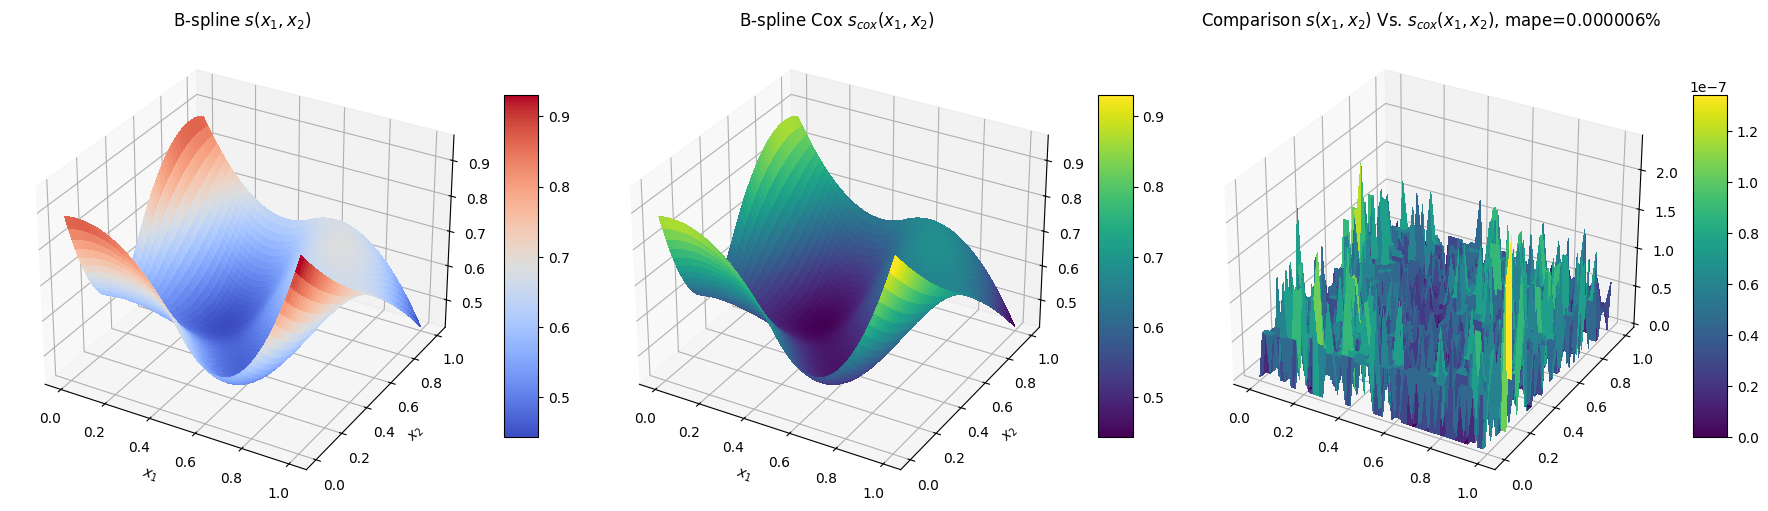

In [4]:
import matplotlib.pyplot as plt
from matplotlib import cm
import numpy as np
torch.manual_seed(42)

# degrees and number of basis functions
n_basis, degree = 4, 2


# Naive implementation from Vasilis
model = bsplines(n_basis, degree)

print('Knot vector in x1 direction (ξ):', model.knot_x) 
print('Knot vector in x2 direction (η):', model.knot_y)
print('\nNodal values (Control point matrix): \n', model.coeffs)


# de Boor-based version
model_deboor = bsplines_deBoor_2D(n_basis, degree)

# share the same control net for a fair comparison
with torch.no_grad():
    model_deboor.coeffs = model.coeffs.clone()


# Domain creation
colloc_points = 50
x1 = torch.linspace(0.0, 0.99999, colloc_points)
x2 = torch.linspace(0.0, 0.99999, colloc_points)
X1, X2 = torch.meshgrid(x1, x2, indexing="ij")
X = torch.stack([X1, X2], dim=-1).reshape(-1, 2)
X.requires_grad_(True)


# Forward pass for both models
s = model.forward(X)
s_cox = model_deboor.forward(X)

# reshape for plotting
s = s.reshape(colloc_points,colloc_points)
s_cox = s_cox.reshape(colloc_points,colloc_points)


fig, (ax1, ax2, ax3) = plt.subplots(
    nrows=1, ncols=3, 
    subplot_kw={"projection": "3d"}, 
    figsize=(18, 6) # Increased width for the two plots
)

# Prepare the grid data
X1, X2 = np.meshgrid(x1.detach().numpy(), x2.detach().numpy())


# --- Subplot 1: B-spline Surface (s) ---
ax1.set_title('B-spline $s(x_1, x_2)$')

surf_s = ax1.plot_surface(
    X1, X2, s.detach().numpy(), 
    cmap=cm.coolwarm, 
    linewidth=0, 
    antialiased=False
)

ax1.set_xlabel('$x_1$')
ax1.set_ylabel('$x_2$')

# Add colorbar for the first subplot
fig.colorbar(surf_s, ax=ax1, shrink=0.6, aspect=10)


# --- Subplot 2: B-spline Cox (s_cox) ---
ax2.set_title('B-spline Cox $s_{cox}(x_1, x_2)$')

surf_cox = ax2.plot_surface(
    X1, X2, s_cox.detach().numpy(), 
    cmap=cm.viridis, # Using a distinct colormap
    linewidth=0, 
    antialiased=False
)

ax2.set_xlabel('$x_1$')
ax2.set_ylabel('$x_2$')

# Add colorbar for the second subplot
fig.colorbar(surf_cox, ax=ax2, shrink=0.6, aspect=10)


# --- Subplot 3: Comaparison  ---

difference = torch.abs(s - s_cox)
mape = torch.mean(difference / (torch.abs(s) + 1e-8)) * 100

ax3.set_title(r'Comparison $s(x_1, x_2)$ Vs. $s_{{cox}}(x_1, x_2)$, mape={:.6f}%'.format(mape.item()))

diff = ax3.plot_surface(
    X1, X2, difference.detach().numpy(), 
    cmap=cm.viridis, # Using a distinct colormap
    linewidth=0, 
    antialiased=False
)

ax2.set_xlabel('$x_1$')
ax2.set_ylabel('$x_2$')

# Add colorbar for the second subplot
fig.colorbar(diff, ax=ax3, shrink=0.6, aspect=10)


# Optional: Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

## Runtime Comparison 

In [ ]:
import time

torch.manual_seed(42)
p_max = 15          # Maximum degree to test
n_basis_max = 15    # Maximum number of basis functions to test
n_test_points = 50  # Number of points for x1 and x2
x1 = torch.linspace(0.0, 0.99999, n_test_points)
x2 = torch.linspace(0.0, 0.99999, n_test_points)
X1, X2 = torch.meshgrid(x1, x2, indexing="ij")
X = torch.stack([X1, X2], dim=-1).reshape(-1, 2)
X.requires_grad_(True)


# --- 1. Varying Degree (p) ---
print("Running test 1: Varying Degree (p)")
# Fixed parameters
n_basis = 18 
degrees_to_test = list(range(1, p_max + 1))
runtime_s_degree = []
runtime_s_cox_degree = []

for p in degrees_to_test:

    # Cox-based version (assuming this is bsplines_2D)
    model = bsplines(n_basis, p)
    
    # De Boor-based version
    model_deboor = bsplines_deBoor_2D(n_basis, p)
    with torch.no_grad():
        model_deboor.coeffs = model.coeffs.clone()

    # Time s (Cox-based)
    start_time = time.perf_counter()
    s = model.forward(X)
    runtime_s_degree.append(time.perf_counter() - start_time)

    # Time s_cox (De Boor-based)
    start_time = time.perf_counter()
    s_cox = model_deboor.forward(X)
    runtime_s_cox_degree.append(time.perf_counter() - start_time)


# --- 2. Varying Number of Basis Functions (n) ---
print("Running test 2: Varying Number of Basis Functions (n)")
# Fixed parameters
p = 2
n_basis_to_test = list(range(3, n_basis_max + 1))
runtime_s_n_basis = []
runtime_s_cox_n_basis = []

for n in n_basis_to_test:

    # Cox-based version
    model = bsplines(n, p)
    
    # De Boor-based version
    model_deboor = bsplines_deBoor_2D(n, p)
    with torch.no_grad():
        model_deboor.coeffs = model.coeffs.clone()

    # Time s (Cox-based)
    start_time = time.perf_counter()
    s = model.forward(X)
    runtime_s_n_basis.append(time.perf_counter() - start_time)

    # Time s_cox (De Boor-based)
    start_time = time.perf_counter()
    s_cox = model_deboor.forward(X)
    runtime_s_cox_n_basis.append(time.perf_counter() - start_time)
    

# --- 3. Plotting Results ---
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

# Plot 1: Runtimes vs. Degree
ax1.plot(degrees_to_test, runtime_s_degree, label='B-spline (s)', marker='o')
ax1.plot(degrees_to_test, runtime_s_cox_degree, label='B-spline Cox-de Boor($s_{cox}$)', marker='x')
ax1.set_title(f'Runtime vs. Polynomial Degree (n={n_basis})')
ax1.set_xlabel('Degree (p)')
ax1.set_ylabel('Execution Time (seconds)')
ax1.set_yscale('log')
ax1.legend()
ax1.grid(True, linestyle='--')

# Plot 2: Runtimes vs. Number of Basis Functions
ax2.plot(n_basis_to_test, runtime_s_n_basis, label='B-spline (s)', marker='o')
ax2.plot(n_basis_to_test, runtime_s_cox_n_basis, label='B-spline Cox-de Boor($s_{cox}$)', marker='x')
ax2.set_title(f'Runtime vs. Number of Basis Functions (p={p})')
ax2.set_xlabel('Number of Basis Functions (n_basis)')
ax2.set_ylabel('Execution Time (seconds)')
ax2.set_yscale('log')
ax2.legend()
ax2.grid(True, linestyle='--')

plt.tight_layout()
plt.show()

Running test 1: Varying Degree (p)
